# What is GFTM getting wrong on R4, and where else? (Fusion_PhD-38e9.28)

Advisory agent analysis. Every number comes from pyro `pyroscan.nc` / `cube.nc` objects on Pitagora; nothing is read
from a CSV. Background (Fusion_PhD `results/beta_stabilisation_f05/README.md`, 38e9.9): above GS2 β ≈ 0.07 GFTM finds a
compact, even-parity, low-ω KBM on R4 that GS2 does not have; it is B∥-driven, rises with WIDTH and is not converged
in NXGRID.

1. **Numerical settings** on R4 (3 ky × 19 β): max basis (NBASIS 59 / NXGRID 65), FILTER, NMODES, IBRANCH,
   USE_MHD_RULE, velocity resolution (NU/NE). Leaves `GFTM/Runs/scan_beta_f05_diag/R4/*` (GyroRun).
2. **Extents** of every GFTM mode (FILTER 0, NMODES 8) against GS2's mode.
3. **Mode selection and frequency**: the whole unstable GFTM spectrum against GS2, and whether a selection rule finds
   the GS2-like mode.
4. **Other bad cases**: the KBM hypercubes, the β scans and the S1_3 q/ŝ scans, and what the badly-wrong cases share.

GS2 is initial-value: one mode per run, so there is no GS2 subdominant mode to compare against.

In [1]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
from scipy.integrate import trapezoid
from dotenv import load_dotenv
import pyrokinetics
from pyrokinetics import PyroScan
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics import Diagnostics
from pyrokinetics.diagnostics.extent import Extent
from general_analysis import mode_classification as mc

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "gftm_r4_diagnosis"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
run_template = "Runs"
plot_dir = ROOT / "Plots" / analysis_name
plot_dir.mkdir(parents=True, exist_ok=True)

case = "R4"
ky_targets = [0.1, 0.2, 0.3]                  # snapped to GS2's grid
beta_high, beta_low = 0.07, 0.05              # GS2 beta numbers: high-beta cells >= 0.07, low-beta control <= 0.05
tol_unconverged = 0.1                         # GS2 growth_rate_tolerance at or above this: unconverged (38e9.9)
fraction = 0.95                               # pyro Extent fraction
gs2_leaf = ("GS2", "scan_beta", "parameter_scan_GS2")
# GFTM leaves on R4: label -> (project, leaf, WIDTH). "base" = FILTER 0.5, NMODES 2, NBASIS 12, NXGRID 32, NU 7, NE 3.
leaves = {
    "base w0.3": ("scan_beta_f05_conv", "width_0p3", 0.3),
    "base w0.8": ("scan_beta_f05", "w0p8", 0.8),
    "base w1.74": ("scan_beta", "parameter_scan_gftm_default", 1.74),   # beta labelled with GS2's numbers (f = 1)
    "nobpar w0.8": ("scan_beta_f05_conv", "nobpar_w0p8", 0.8),
    **{f"maxb w{w:g}": ("scan_beta_f05_diag", f"maxb_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8, 1.74)},
    **{f"spec w{w:g}": ("scan_beta_f05_diag", f"spec_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8, 1.74)},
    "spec maxb w0.8": ("scan_beta_f05_diag", "spec_maxb_w0p8", 0.8),
    "ibranch0 w0.8": ("scan_beta_f05_diag", "ibr0_w0p8", 0.8),
    "filter0.7 w0.8": ("scan_beta_f05_diag", "filt0p7_w0p8", 0.8),
    "filter0.9 w0.8": ("scan_beta_f05_diag", "filt0p9_w0p8", 0.8),
    "mhd w0.8": ("scan_beta_f05_diag", "mhd_w0p8", 0.8),
    "mhd nobpar w0.8": ("scan_beta_f05_diag", "mhd_nobpar_w0p8", 0.8),
    **{f"vel w{w:g}": ("scan_beta_f05_diag", f"vel_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8)},
}
fs_title, fs_label, fs_tick, fs_legend = 16, 16, 14, 12
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}

pyrokinetics 0.9.2.dev149+gf119e687


## Load R4: GS2 and every GFTM leaf
Each leaf is a PyroScan with its `pyroscan.nc`; pyro `Extent` (95%) is added per field and mode. GFTM's ky grid is
selected onto GS2's three ky (asserted), and β is matched by index (GFTM stores pyro β = GS2 β × f, asserted constant).

In [2]:
def v(da):
    return np.asarray(getattr(da.data, "magnitude", da.data))


def load_leaf(code, project, leaf):
    d = data_root / code / run_template / project / case / leaf
    s = PyroScan(pyroscan_json=d / "pyroscan.json", load_base_pyro=True)
    s.load_gk_output(netcdf_file=d / "pyroscan.nc")
    Extent(s.gk_output, fraction=fraction)
    out = s.gk_output.data
    for dim in ("bpar", "kx"):   # nobpar leaves scan numerics.bpar = [False]; GFTM writes a length-1 kx
        out = out.squeeze(dim, drop=True) if dim in out.dims else out
    return out


gs2_all = load_leaf(*gs2_leaf)
iky = [int(np.abs(v(gs2_all.ky) - k).argmin()) for k in ky_targets]
G = gs2_all.isel(ky=iky).transpose("ky", "beta", ...)
beta = v(G.beta)
ky = v(G.ky)
tol = v(G.growth_rate_tolerance)
unconv = tol >= tol_unconverged
hi, lo = beta >= beta_high, beta <= beta_low
g_gs2, w_gs2 = v(G.growth_rate), v(G.mode_frequency)

R = {}
for lab, (project, leaf, _) in leaves.items():
    d = load_leaf("GFTM", project, leaf)
    d = d.sel(ky=ky, method="nearest").transpose("ky", "beta", "mode", ...)
    assert np.allclose(v(d.ky), ky, atol=1e-3) and d.beta.size == beta.size, lab
    f = v(d.beta) / beta
    assert np.allclose(f, f[0], rtol=1e-3), (lab, "beta is not GS2 beta x constant")
    R[lab] = d
print("ky", ky.round(3), "| GS2 beta", beta.round(2))
print("modes per leaf:", {lab: int(d.mode.size) for lab, d in R.items()})
print("GS2 unconverged (tol >= 0.1) at beta >= 0.07:", int(unconv[:, hi].sum()), "of", int(hi.sum() * len(ky)))

ky [0.112 0.2   0.3  ] | GS2 beta [0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13 0.14
 0.15 0.16 0.17 0.18 0.19]
modes per leaf: {'base w0.3': 2, 'base w0.8': 2, 'base w1.74': 2, 'nobpar w0.8': 2, 'maxb w0.3': 2, 'maxb w0.8': 2, 'maxb w1.74': 2, 'spec w0.3': 8, 'spec w0.8': 8, 'spec w1.74': 8, 'spec maxb w0.8': 8, 'ibranch0 w0.8': 2, 'filter0.7 w0.8': 2, 'filter0.9 w0.8': 2, 'mhd w0.8': 2, 'mhd nobpar w0.8': 2, 'vel w0.3': 2, 'vel w0.8': 2}
GS2 unconverged (tol >= 0.1) at beta >= 0.07: 31 of 39


## (2) and (3) The whole GFTM spectrum against GS2
FILTER 0 / NMODES 8: GFTM returns up to 8 unstable modes per cell (`sort_eigenvalues` keeps only γ > 0, so stable
modes are never output). Each mode is typed by the T + ω rule of `docs/mode_filtering.md` (KBM: T < 0.05 and ω > 0;
MTM: T > 0.15 and ω < 0; else mixed); T is the stored `tearing_parameter`.

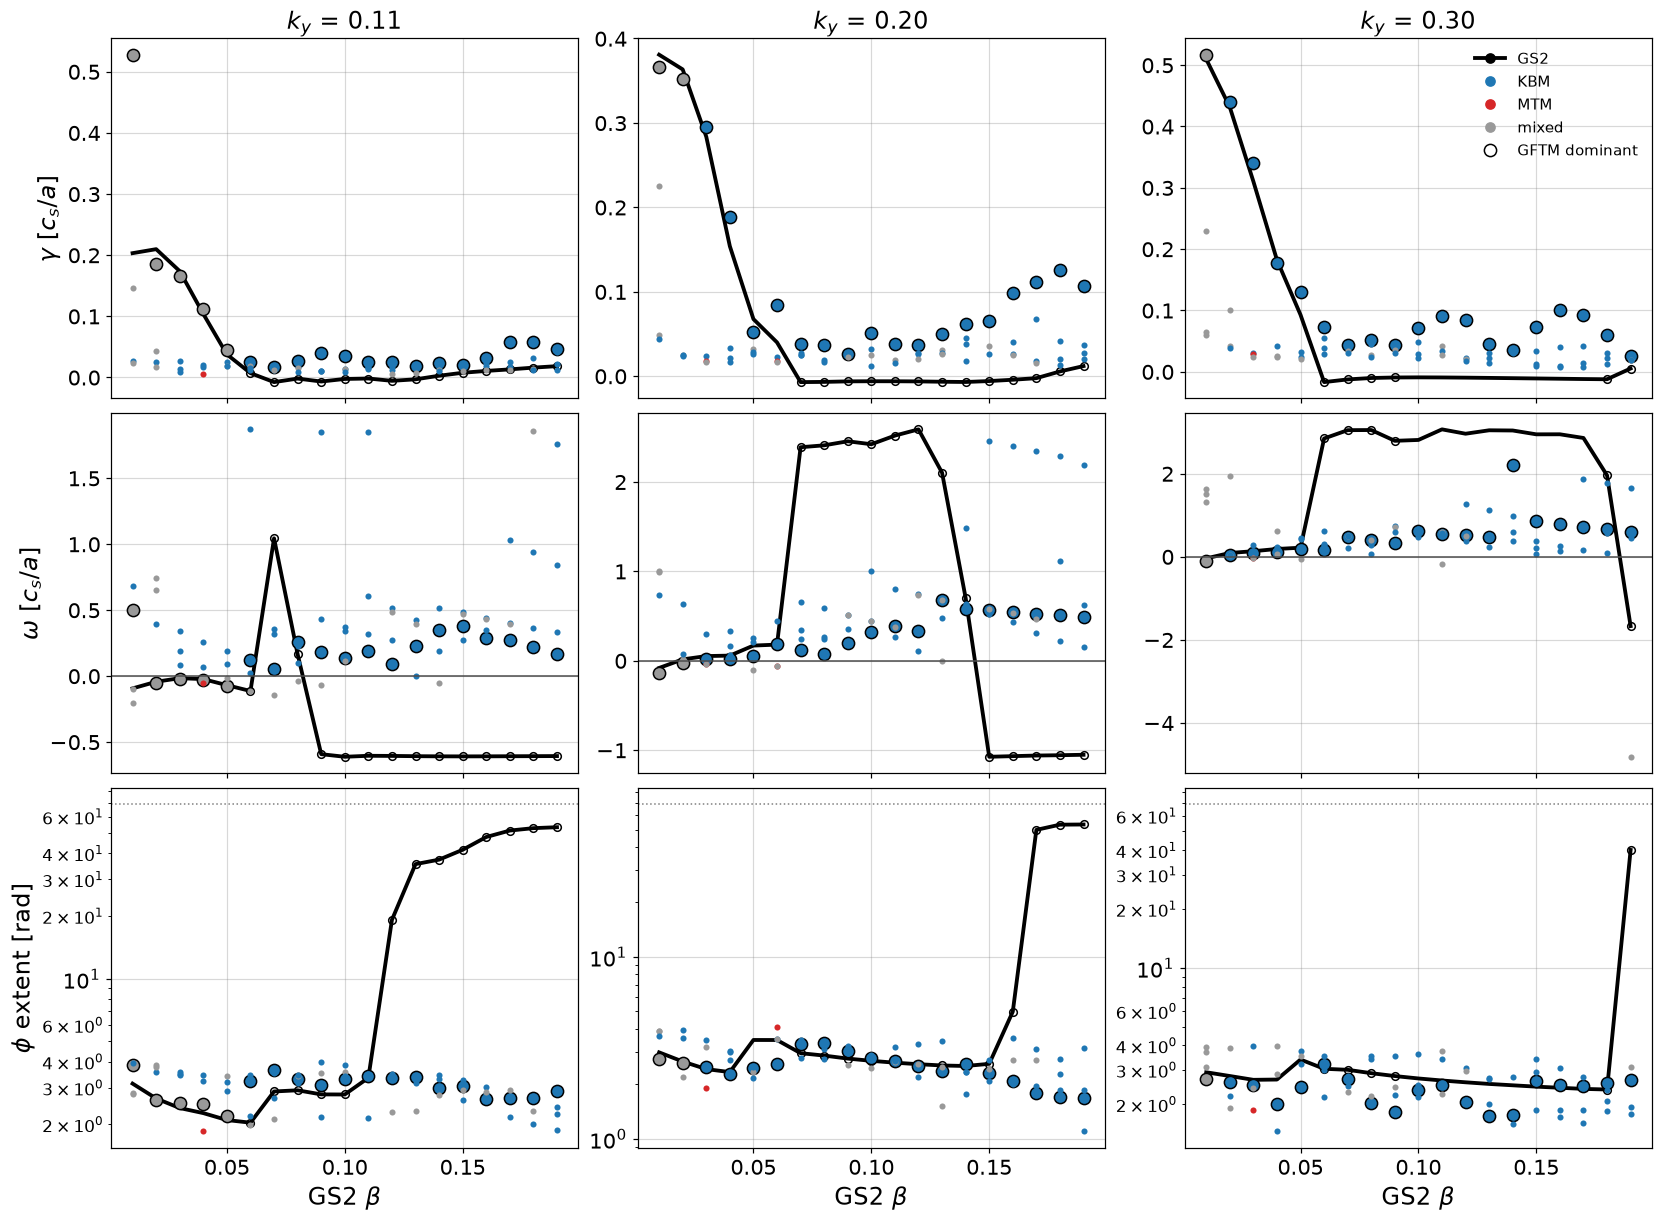

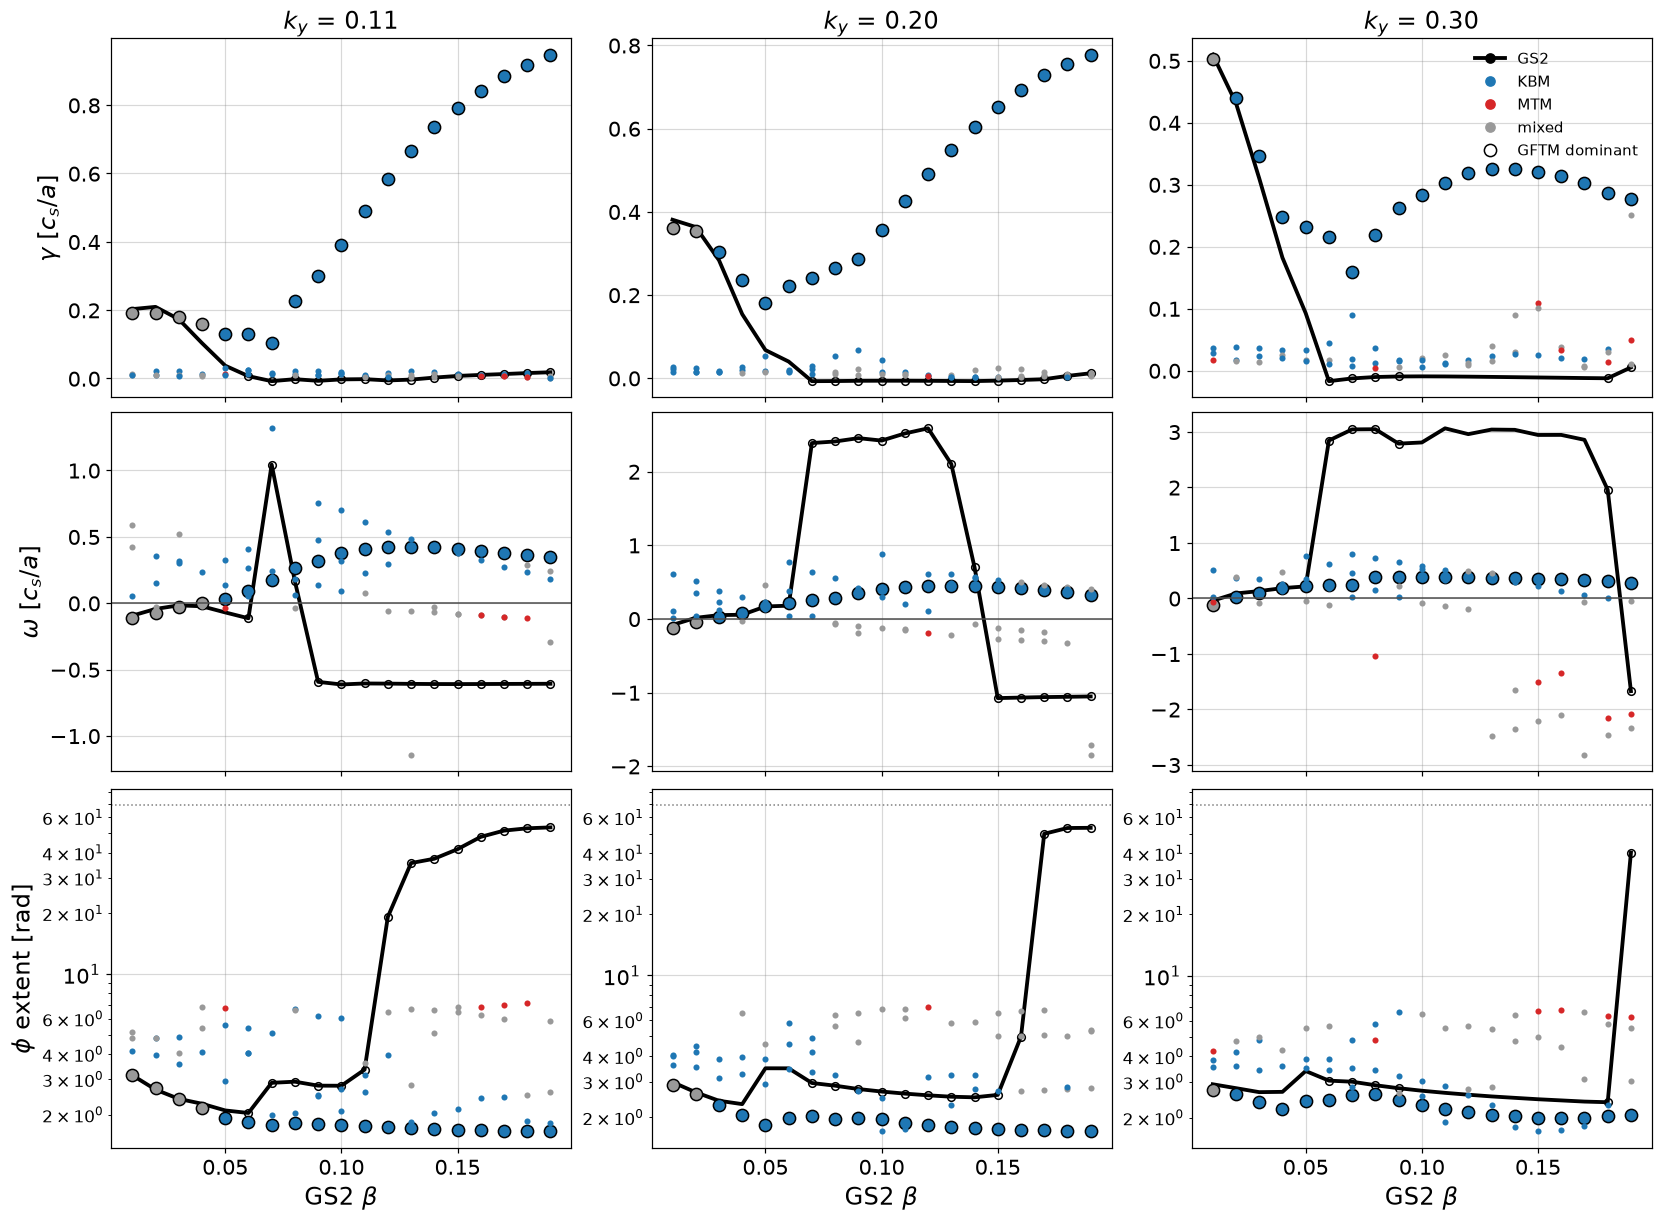

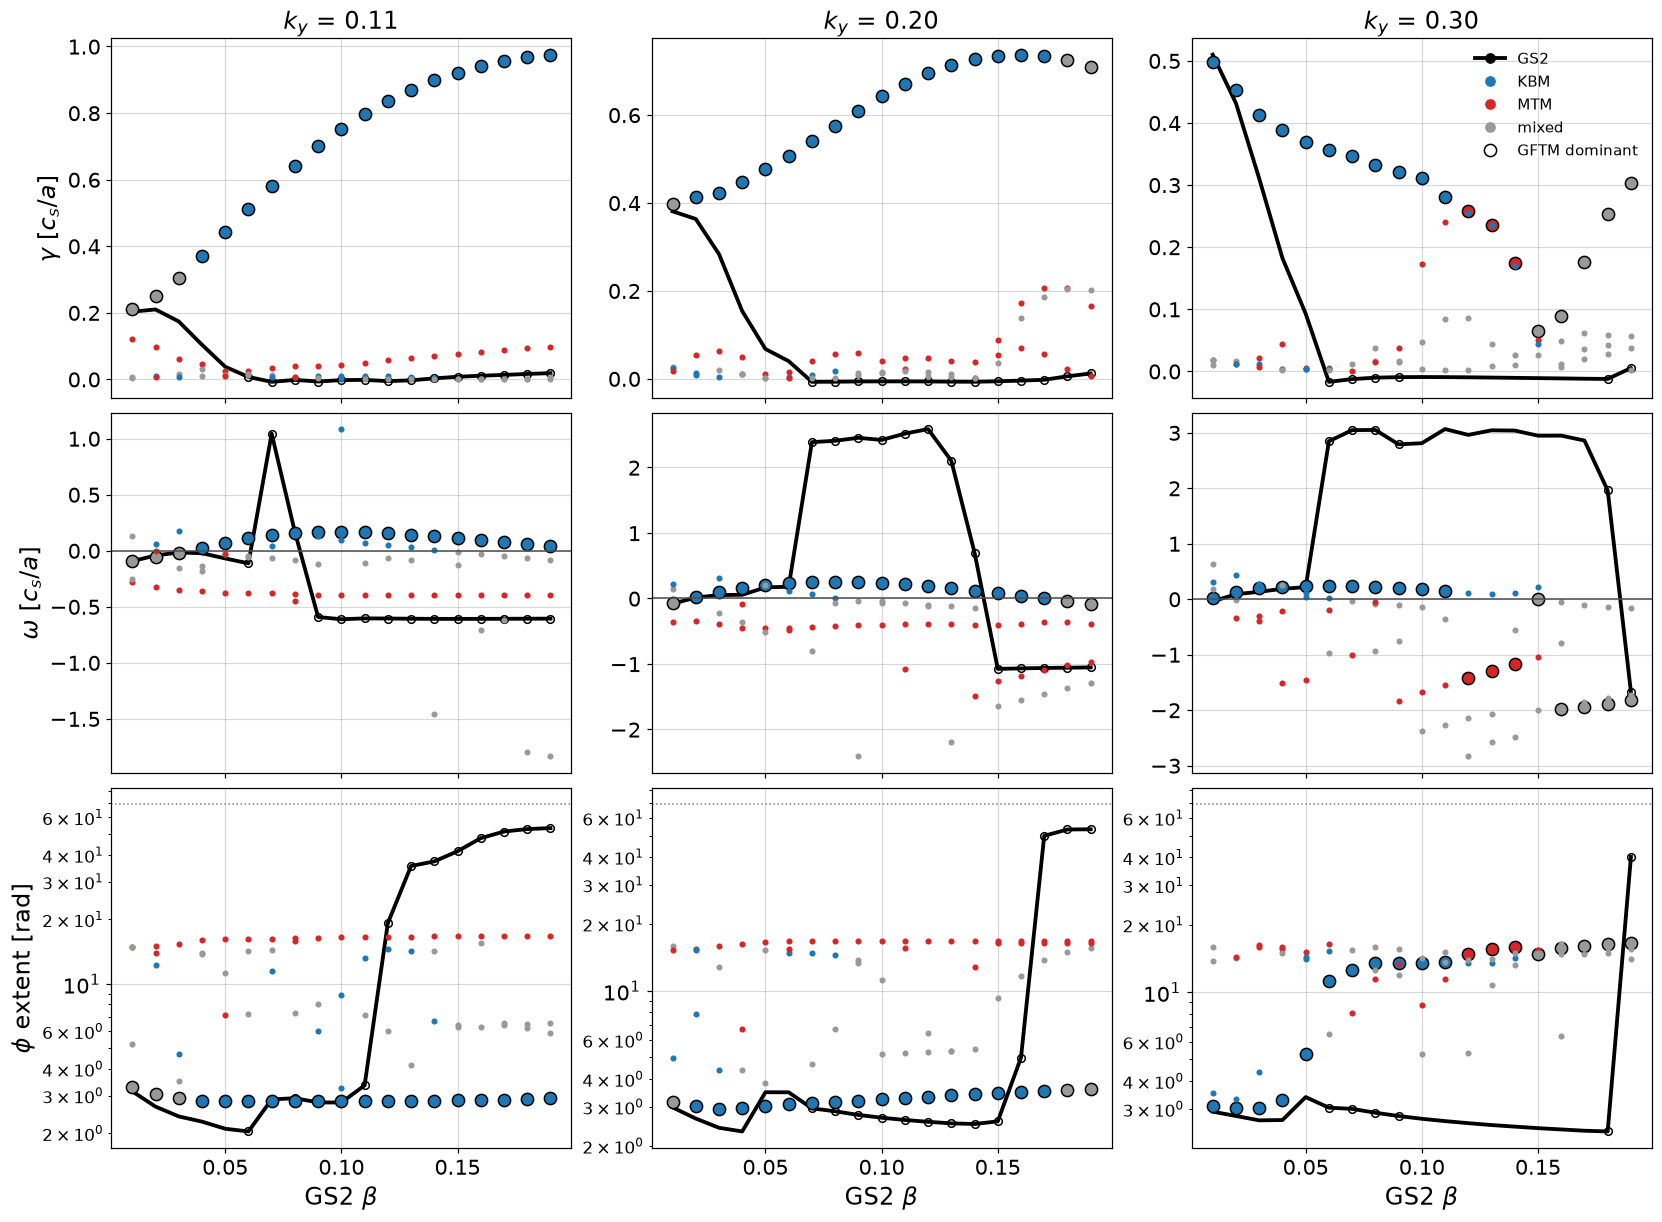

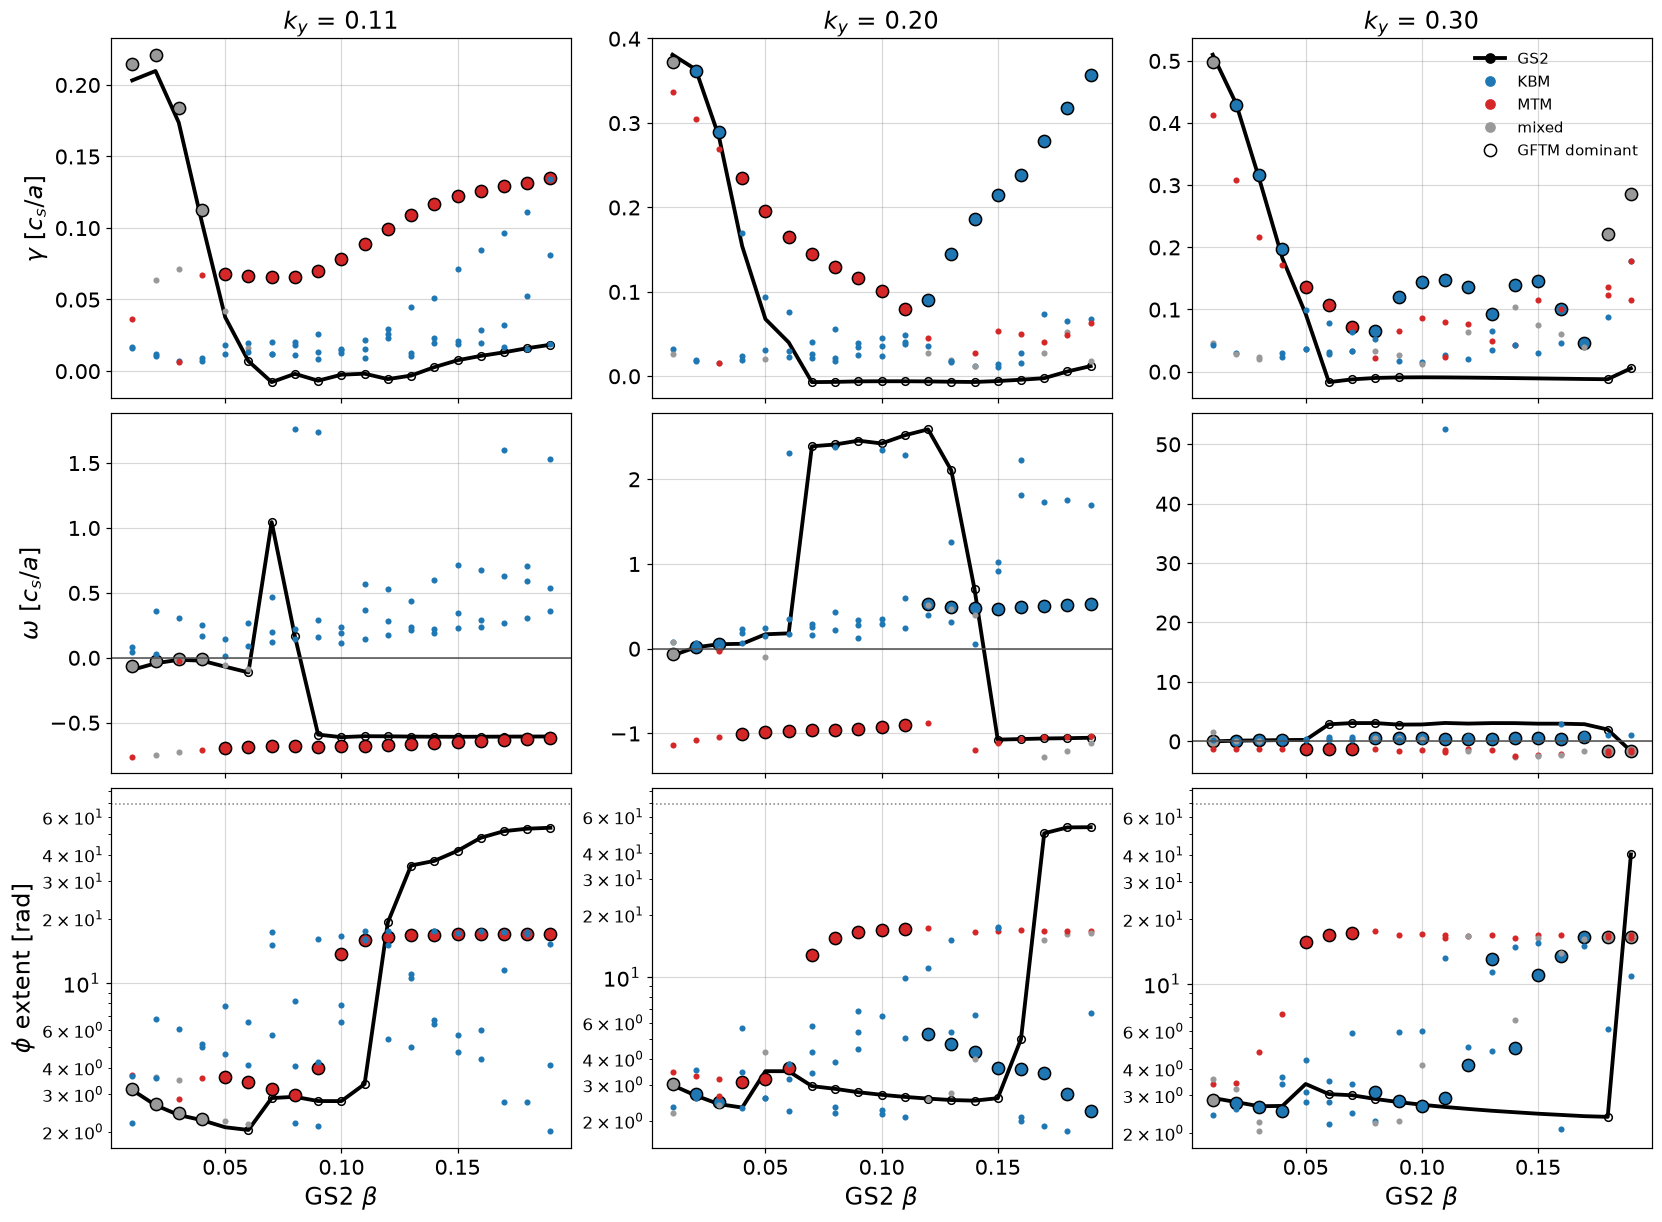

spec w0.3: unstable modes per high-beta cell: median 4, max 4
   KBM   n 129: omega +0.10..+1.87, gamma max 0.125, phi extent 1.7..3.5
   mixed n  27: omega -0.16..+0.73, gamma max 0.041, phi extent 2.1..3.5
spec w0.8: unstable modes per high-beta cell: median 4, max 4
   KBM   n  95: omega +0.06..+0.71, gamma max 0.948, phi extent 1.7..5.3
   MTM   n   9: omega -2.13..-0.10, gamma max 0.109, phi extent 5.4..7.1
   mixed n  52: omega -2.40..+0.46, gamma max 0.251, phi extent 2.7..6.8
spec w1.74: unstable modes per high-beta cell: median 4, max 4
   KBM   n  43: omega +0.01..+0.25, gamma max 0.975, phi extent 2.8..14.6
   MTM   n  43: omega -1.53..-0.37, gamma max 0.257, phi extent 11.4..16.8
   mixed n  69: omega -2.40..-0.04, gamma max 0.725, phi extent 4.9..16.2
spec maxb w0.8: unstable modes per high-beta cell: median 4, max 4
   KBM   n 100: omega +0.14..+2.23, gamma max 0.357, phi extent 2.1..17.4
   MTM   n  40: omega -2.16..-0.63, gamma max 0.178, phi extent 3.9..17.3
   mixed n

In [7]:
spec_leaves = ["spec w0.3", "spec w0.8", "spec w1.74", "spec maxb w0.8"]
type_colour = {"KBM": "C0", "MTM": "C3", "mixed": "0.6"}
box = float(np.ptp(v(G.theta)))
ext_gs2 = v(G.extent.sel(field="phi"))


def mode_types(d):
    return mc.classify_T_omega({"T": v(d.tearing_parameter), "omega": mc.ION_DIRECTION * v(d.mode_frequency)})


figs_spec = {}
for lab in spec_leaves:
    d = R[lab]
    gm, wm, em = v(d.growth_rate), v(d.mode_frequency), v(d.extent.sel(field="phi"))
    typ, dm = mode_types(d), np.nan_to_num(gm, nan=-np.inf).argmax(-1)
    fig, axes = plt.subplots(3, len(ky), figsize=(5 * len(ky), 11), sharex=True)
    for col in range(len(ky)):
        for row, (y, ref) in enumerate(((gm, g_gs2), (wm, w_gs2), (em, ext_gs2))):
            ax = axes[row, col]
            ax.plot(beta, ref[col], color="k", lw=2.5, marker="none")
            ax.plot(beta[unconv[col]], ref[col, unconv[col]], color="k", ls="", marker="o", ms=5, mfc="none")
            for j in range(beta.size):
                for m in range(d.mode.size):
                    if np.isfinite(gm[col, j, m]) and gm[col, j, m] > 0:
                        big = m == dm[col, j]
                        ax.plot(beta[j], y[col, j, m], ls="", marker="o", ms=8 if big else 4, color=type_colour[typ[col, j, m]],
                                mec="k" if big else "none")
            ax.tick_params(labelsize=fs_tick)
        axes[1, col].axhline(0, color="0.3", lw=1, marker="")
        axes[2, col].axhline(box, color="0.5", ls=":", lw=1, marker="")
        axes[2, col].set_yscale("log")
        axes[0, col].set_title(rf"$k_y$ = {ky[col]:.2f}", fontsize=fs_title)
        axes[-1, col].set_xlabel(r"GS2 $\beta$", fontsize=fs_label)
    for row, yl in enumerate((r"$\gamma$ [$c_s/a$]", r"$\omega$ [$c_s/a$]", r"$\phi$ extent [rad]")):
        axes[row, 0].set_ylabel(yl, fontsize=fs_label)
    axes[0, -1].legend(handles=[Line2D([], [], color="k", lw=2.5, label="GS2"),
                                *[Line2D([], [], color=c, ls="", marker="o", label=t) for t, c in type_colour.items()],
                                Line2D([], [], color="w", mec="k", ls="", marker="o", ms=8, label="GFTM dominant")], fontsize=10)
    fig.savefig(plot_dir / f"gftm_all_modes_vs_beta_r4_{lab.replace(' ', '_').replace('.', 'p')}.png", dpi=150, bbox_inches="tight")
    figs_spec[lab] = fig
plt.show()

for lab in spec_leaves:
    d = R[lab]
    gm, wm, em = v(d.growth_rate), v(d.mode_frequency), v(d.extent.sel(field="phi"))
    typ = mode_types(d)
    ok = np.isfinite(gm) & (gm > 0) & hi[None, :, None]
    n = ok.sum((0, 1))
    print(f"{lab}: unstable modes per high-beta cell: median {np.median(ok.sum(-1)):.0f}, max {ok.sum(-1).max()}")
    for t in type_colour:
        s = ok & (typ == t)
        if s.any():
            print(f"   {t:5s} n {s.sum():3d}: omega {np.percentile(wm[s], 5):+.2f}..{np.percentile(wm[s], 95):+.2f}, "
                  f"gamma max {gm[s].max():.3f}, phi extent {np.percentile(em[s], 5):.1f}..{np.percentile(em[s], 95):.1f}")
print("GS2 high-beta cells: omega", np.nanmin(w_gs2[:, hi]).round(2), "..", np.nanmax(w_gs2[:, hi]).round(2),
      "| phi extent", np.nanmin(ext_gs2[:, hi]).round(1), "..", np.nanmax(ext_gs2[:, hi]).round(1))
print("GS2 low-beta cells:  omega", np.nanmin(w_gs2[:, lo]).round(2), "..", np.nanmax(w_gs2[:, lo]).round(2),
      "| phi extent", np.nanmin(ext_gs2[:, lo]).round(1), "..", np.nanmax(ext_gs2[:, lo]).round(1))